# BÀI THỰC HÀNH TỔNG HỢP: AI HỖ TRỢ GIÁM SÁT VÀ ĐIỀU PHỐI KỸ THUẬT NÔNG NGHIỆP

**Học phần:** Trí tuệ nhân tạo (COS521) - Cử nhân Công nghệ thông tin  
**Giảng viên:** PGS.TS. Đoàn Thanh Nghị  
**Thời lượng:** 05 tiết thực hành, mỗi tiết 50 phút - tổng 250 phút  
**Hình thức:** Cá nhân hoặc nhóm 2 sinh viên; mỗi sinh viên phải giải thích được toàn bộ phần mình nộp

Họ tên: … · MSSV: … · Lớp: … · Nhóm: … · Ngày thực hành: …

## Bối cảnh thực tiễn

Một hợp tác xã (HTX) có nhiều lô trồng. Dữ liệu cảm biến và quan sát thực địa được dùng để dự báo lô có **nguy cơ stress/sâu bệnh cần kiểm tra sớm**. Nguồn lực kỹ thuật có hạn nên hệ thống phải:

1. kiểm tra và chuẩn bị dữ liệu;
2. so sánh Cây quyết định và Gaussian Naive Bayes;
3. chọn ngưỡng cảnh báo dựa trên chi phí bỏ sót;
4. xác định lô ưu tiên;
5. dùng A* lập tuyến đường có chi phí thấp đến lô đó;
6. xuất một bảng khuyến nghị có thể kiểm tra, không tự động thay thế chuyên gia.

**Dữ liệu trong notebook là dữ liệu mô phỏng có seed cố định**, chỉ dùng học tập. Nhãn `risk=1` biểu thị “cần kiểm tra sớm”, không phải chẩn đoán bệnh. Không dùng kết quả để ra quyết định sản xuất thực tế.

## Mục tiêu học tập

Sau bài này, sinh viên có thể xác định T-E-P; phòng tránh rò rỉ dữ liệu; đánh giá mô hình bằng cross-validation; giải thích cây và xác suất Bayes; phân biệt xác suất với quyết định; tối ưu ngưỡng theo chi phí; cài đặt A*; tích hợp dự báo và tìm kiếm thành một quy trình tái lập.

| Thời gian | Hoạt động | Sản phẩm |
|---:|---|---|
| 0-20 phút | Đọc tình huống, xác định T-E-P, chạy môi trường | Phát biểu bài toán |
| 20-55 phút | Khám phá và kiểm tra dữ liệu | Bảng chất lượng dữ liệu |
| 55-110 phút | So sánh Cây quyết định - GaussianNB | Bảng CV, mô hình được chọn |
| 110-120 phút | Nghỉ | |
| 120-160 phút | Ngưỡng cảnh báo theo chi phí | Bảng chi phí, ngưỡng chốt |
| 160-205 phút | A* và bản đồ chi phí | Tuyến đường, kiểm thử |
| 205-235 phút | Tích hợp thành khuyến nghị | Bảng điều phối HTX |
| 235-250 phút | Báo cáo, tự kiểm tra, vấn đáp | Notebook có output |

## Quy tắc thực nghiệm

- Chia development/test một lần, có phân tầng; không dùng test để chọn mô hình hoặc ngưỡng.
- Mọi bước học tham số phải nằm trong cross-validation hoặc Pipeline.
- Accuracy không đủ khi chi phí bỏ sót cao; báo cáo confusion matrix, recall lớp nguy cơ và chi phí.
- Xác suất dự đoán không mặc nhiên được hiệu chuẩn; ngưỡng trong bài là minh họa ra quyết định theo chi phí.
- Đường ngắn nhất theo số bước có thể không phải đường rẻ nhất khi địa hình có trọng số.
- Mã mẫu phải chạy bằng **Runtime → Restart session → Run all**; các ô TODO mặc định tắt.

**Căn cứ nội dung:** COS521 gồm tìm kiếm mù/heuristic, A*, Cây quyết định và Bayes thơ ngây; bài thực hành này tích hợp các CLO phân tích, lập trình, đánh giá và làm việc nhóm trong một tình huống ứng dụng.

In [1]:
import sys, heapq, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
SEED=42
rng=np.random.default_rng(SEED)
CHECKS=[]
def check(name, condition):
    assert bool(condition), name
    CHECKS.append(name); print('PASS:',name)
print('Python:',sys.version.split()[0],'| scikit-learn:',sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


## 1. Tạo bộ dữ liệu mô phỏng và phát biểu T-E-P

Mỗi hàng là một lần quan sát lô trồng:

| Biến | Ý nghĩa | Miền hợp lệ mô phỏng |
|---|---|---|
| soil_moisture | Ẩm đất (%) | 5-65 |
| leaf_temp | Nhiệt độ lá (°C) | 22-43 |
| humidity | Ẩm không khí (%) | 35-95 |
| ndvi | Chỉ số sinh trưởng | 0,15-0,92 |
| pest_count | Số côn trùng ghi nhận/bẫy | 0-30 |
| rain_24h | Mưa 24 giờ (mm) | 0-80 |
| risk | 1: cần kiểm tra sớm; 0: chưa cảnh báo | nhãn |

Nhãn được sinh từ một hàm ẩn có nhiễu, tạo ra quan hệ không tuyến tính và tương tác. Mục tiêu không phải đạt điểm tuyệt đối mà là xây dựng quy trình đúng.

**T-E-P:** Task = phân loại nguy cơ và điều phối; Experience = quan sát có nhãn trong development; Performance = macro-F1, recall lớp nguy cơ, chi phí quyết định trên dữ liệu chưa dùng để học/chọn.

In [2]:
N=600
soil=np.clip(rng.normal(35,12,N),5,65)
leaf=np.clip(rng.normal(31,4,N),22,43)
humidity=np.clip(rng.normal(68,14,N),35,95)
ndvi=np.clip(rng.normal(.62,.15,N),.15,.92)
pest=np.clip(rng.poisson(6,N),0,30)
rain=np.clip(rng.gamma(1.7,9,N),0,80)
latent=(1.15*(soil<24)+1.0*(leaf>34)+1.35*(ndvi<.48)+1.25*(pest>=9)
        +.65*((humidity>82)&(leaf>31))+.6*((rain>35)&(pest>=7))
        -.45*((soil>32)&(ndvi>.68))+rng.normal(0,1.15,N))
prob=1/(1+np.exp(-(latent-2.15)))
risk=rng.binomial(1,prob)
data=pd.DataFrame({'soil_moisture':soil,'leaf_temp':leaf,'humidity':humidity,
                   'ndvi':ndvi,'pest_count':pest,'rain_24h':rain,'risk':risk})
features=list(data.columns[:-1])
display(data.head())
display(data.describe().T)
print(data.risk.value_counts().rename(index={0:'no_alert',1:'early_check'}))
check('600 quan sát',data.shape==(600,7))
check('Không thiếu dữ liệu',not data.isna().any().any())
check('Nhãn nhị phân',set(data.risk)=={0,1})
check('Tỷ lệ nguy cơ không cực đoan',.15<data.risk.mean()<.75)

risk
no_alert       436
early_check    164
Name: count, dtype: int64
PASS: 600 quan sát
PASS: Không thiếu dữ liệu
PASS: Nhãn nhị phân
PASS: Tỷ lệ nguy cơ không cực đoan


,soil_moisture,leaf_temp,humidity,ndvi,pest_count,rain_24h,risk
0,38.656605,33.061642,49.484424,0.614044,8,13.870175,0
1,22.520191,28.689844,61.193282,0.686368,7,21.005803,0
2,44.005414,36.097789,73.883174,0.574336,8,11.704327,0
3,46.286777,28.489650,66.566446,0.558553,5,5.083435,0
4,11.587578,28.453539,58.892109,0.633853,6,3.634891,1


,count,mean,std,min,25%,50%,75%,max
soil_moisture,600.0,34.677958,11.603978,5.000000,26.626394,34.744016,42.048720,65.000000
leaf_temp,600.0,30.949596,3.924492,22.000000,28.445787,31.039902,33.470145,43.000000
humidity,600.0,66.790504,14.106019,35.000000,57.826705,67.031314,76.449870,95.000000
ndvi,600.0,0.611663,0.146972,0.160433,0.511519,0.624756,0.711358,0.920000
pest_count,600.0,5.816667,2.473848,0.000000,4.000000,6.000000,7.000000,16.000000
rain_24h,600.0,15.316869,11.490057,0.146425,7.280595,12.025354,20.788058,71.542102
risk,600.0,0.273333,0.446042,0.000000,0.000000,0.000000,1.000000,1.000000


### Nhiệm vụ 1 - Kiểm tra dữ liệu và T-E-P (1,0 điểm)

Hoàn thành `audit_student`. Hàm phải trả một DataFrame gồm: kiểu dữ liệu, số thiếu, số giá trị duy nhất, min, max, số giá trị ngoài miền cho từng cột đặc trưng. Không sửa dữ liệu gốc. Sau kiểm thử, viết 100-150 từ: đơn vị quan sát là gì, nhãn là gì, T-E-P là gì, dữ liệu mô phỏng khác dữ liệu thực tế ở đâu, và ít nhất hai kiểm tra cần bổ sung khi thu dữ liệu cảm biến thật.

In [3]:
RANGES={'soil_moisture':(5,65),'leaf_temp':(22,43),'humidity':(35,95),
        'ndvi':(.15,.92),'pest_count':(0,30),'rain_24h':(0,80)}
def audit_student(df, ranges):
    # TODO: mỗi dòng tương ứng một cột trong ranges
    # columns: dtype, missing, unique, min, max, out_of_range
    raise NotImplementedError
RUN_NV1=False
if RUN_NV1:
    audit=audit_student(data,RANGES)
    assert list(audit.index)==list(RANGES)
    assert set(['dtype','missing','unique','min','max','out_of_range'])<=set(audit.columns)
    assert audit['missing'].sum()==0 and audit['out_of_range'].sum()==0
    display(audit)
    print('NV1 đạt kiểm thử; vẫn phải nộp phần phân tích.')
else: print('NV1 chưa hoàn thành.')

NV1 chưa hoàn thành.


## 2. Chia dữ liệu đúng và xây baseline

20% được khóa làm test cuối; 80% là development. Mọi lựa chọn mô hình/ngưỡng chỉ dùng development. `stratify=y` giữ tỷ lệ lớp gần nhau. Baseline luôn đoán lớp phổ biến giúp tránh kết luận từ một con số có vẻ cao nhưng không có điểm đối chiếu.

In [4]:
X=data[features].copy(); y=data.risk.copy()
Xdev,Xtest,ydev,ytest=train_test_split(X,y,test_size=.2,stratify=y,random_state=SEED)
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
baseline=DummyClassifier(strategy='most_frequent')
base_scores=cross_validate(baseline,Xdev,ydev,cv=cv,
    scoring={'f1_macro':'f1_macro','recall_risk':'recall','accuracy':'accuracy'})
print('Development:',Xdev.shape,'| Test khóa:',Xtest.shape)
print({k:round(v.mean(),4) for k,v in base_scores.items() if k.startswith('test_')})
check('Không giao chỉ số',set(Xdev.index).isdisjoint(Xtest.index))
check('Đủ chỉ số',set(Xdev.index)|set(Xtest.index)==set(X.index))
check('Chia 480/120',len(Xdev)==480 and len(Xtest)==120)
check('Tỷ lệ lớp gần nhau',abs(ydev.mean()-ytest.mean())<.03)

Development: (480, 6) | Test khóa: (120, 6)
{'test_f1_macro': np.float64(0.421), 'test_recall_risk': np.float64(0.0), 'test_accuracy': np.float64(0.7271)}
PASS: Không giao chỉ số
PASS: Đủ chỉ số
PASS: Chia 480/120
PASS: Tỷ lệ lớp gần nhau


## 3. So sánh Cây quyết định và Gaussian Naive Bayes

- Cây quyết định học luật ngưỡng, dễ giải thích nhưng có thể quá khớp và không ổn định.
- GaussianNB giả định từng biến có phân phối Gaussian theo lớp và độc lập có điều kiện. Đây là mô hình nhanh, nhưng tương quan và phân phối lệch có thể làm posterior quá tự tin.
- So sánh phải dùng cùng các fold. Trong bài này, lựa chọn theo macro-F1 trung bình; recall và độ lệch chuẩn là thông tin bổ sung.

In [5]:
models={
 'Tree_d4':DecisionTreeClassifier(max_depth=4,min_samples_leaf=10,random_state=SEED),
 'GaussianNB':GaussianNB(var_smoothing=1e-8)}
rows=[]
for name,model in models.items():
    s=cross_validate(model,Xdev,ydev,cv=cv,
      scoring={'f1_macro':'f1_macro','recall_risk':'recall','accuracy':'accuracy'},return_train_score=True)
    rows.append([name,s['train_f1_macro'].mean(),s['test_f1_macro'].mean(),
                 s['test_f1_macro'].std(),s['test_recall_risk'].mean(),s['test_accuracy'].mean()])
cv_table=pd.DataFrame(rows,columns=['model','train_macro_F1','CV_macro_F1','CV_std',
                                    'CV_recall_risk','CV_accuracy']).set_index('model')
display(cv_table)
check('Hai mô hình được đánh giá',len(cv_table)==2)
check('Điểm hợp lệ',cv_table.select_dtypes('number').apply(lambda s:s.between(0,1).all()).all())

PASS: Hai mô hình được đánh giá
PASS: Điểm hợp lệ


,train_macro_F1,CV_macro_F1,CV_std,CV_recall_risk,CV_accuracy
model,,,,,
Tree_d4,0.719146,0.579624,0.029563,0.305413,0.697917
GaussianNB,0.582838,0.574344,0.054004,0.235328,0.733333


### Nhiệm vụ 2 - Lựa chọn độ phức tạp cây (1,5 điểm)

Dùng `GridSearchCV` trên development, scoring=`f1_macro`, cùng `cv`, tìm trong:

- `max_depth`: 2, 3, 4, 5, None;
- `min_samples_leaf`: 1, 5, 10, 20;
- `criterion`: gini, entropy.

Xuất 10 cấu hình tốt nhất gồm mean/std F1 và mean train F1. Chốt một cấu hình; nếu nhiều cấu hình gần nhau (chênh ≤0,01), được chọn cây đơn giản hơn nhưng phải nêu quy tắc trước khi xem test. Vẽ cây tối đa 4 tầng hoặc xuất luật. Nhận xét 150-200 từ về train-CV gap, độ ổn định và giới hạn giải thích.

In [6]:
RUN_NV2=False
if RUN_NV2:
    # TODO: GridSearchCV; bảng 10 cấu hình; chọn và fit trên toàn Xdev
    # Gợi ý kiểm tra sau khi hoàn thành:
    # assert selected_tree.tree_.n_node_samples[0]==len(Xdev)
    # assert selected_tree.get_n_leaves()>=2
    raise NotImplementedError('Hoàn thành NV2 trước khi bật cờ')
else: print('NV2 chưa hoàn thành.')

NV2 chưa hoàn thành.


### Nhiệm vụ 3 - Đối chiếu Bayes và giải thích một dự đoán (1,0 điểm)

Fit GaussianNB trên toàn development. Với một mẫu development do giảng viên chỉ định `sample_id = Xdev.index[0]`, tự tính log-score:

$$\log P(c)+\sum_j -\frac{1}{2}\left[\log(2\pi\sigma_{cj}^2)+\frac{(x_j-\mu_{cj})^2}{\sigma_{cj}^2}\right].$$

Chuẩn hóa bằng log-sum-exp và đối chiếu `predict_proba` (sai số ≤1e-9). Tạo bảng đóng góp log-likelihood theo biến và lớp. Nêu rõ đây là giải thích theo giả định mô hình, không phải quan hệ nhân quả; xác suất cao không bảo đảm hiệu chuẩn tốt.

In [7]:
def gaussian_log_scores_student(model, x_row):
    # TODO: trả vector log-score theo model.classes_; dùng model.theta_, model.var_, model.class_prior_
    raise NotImplementedError
RUN_NV3=False
if RUN_NV3:
    gnb=GaussianNB(var_smoothing=1e-8).fit(Xdev,ydev)
    sample=Xdev.iloc[0]
    log_s=gaussian_log_scores_student(gnb,sample)
    w=np.exp(log_s-log_s.max()); posterior=w/w.sum()
    assert np.allclose(posterior,gnb.predict_proba(sample.to_frame().T)[0],atol=1e-9)
    print('NV3 đạt đối chiếu:',posterior)
else: print('NV3 chưa hoàn thành.')

NV3 chưa hoàn thành.


## 4. Chọn ngưỡng cảnh báo theo chi phí

Mặc định `predict` dùng ranh giới xác suất khoảng 0,5. Nhưng trong điều phối HTX, **bỏ sót lô nguy cơ** có thể tốn kém hơn một chuyến kiểm tra thừa. Quy ước minh họa:

- False Negative (bỏ sót): 5 đơn vị chi phí;
- False Positive (kiểm tra thừa): 1 đơn vị;
- True Positive/True Negative: 0 trong hàm chi phí giản lược.

Không chọn ngưỡng trên test. Ta dùng **out-of-fold probability** trên development: mỗi xác suất được tạo bởi mô hình không học từ chính hàng đó. Sau khi chốt ngưỡng, fit mô hình trên toàn development và chỉ đánh giá test một lần.

Chi phí này là giả định cho bài học, chưa phải ước lượng kinh tế thực tế. Trong triển khai cần xác định chi phí với HTX, kiểm tra độ nhạy và năng lực xử lý cảnh báo.

Ngưỡng minh họa đã chốt: 0.15
PASS: Mỗi mẫu có một OOF probability
PASS: Xác suất OOF hợp lệ
PASS: Ngưỡng nằm trong lưới


,threshold,tn,fp,fn,tp,cost,recall,precision
0,0.10,107,242,20,111,342,0.847328,0.314448
1,0.15,190,159,34,97,329,0.740458,0.378906
2,0.20,192,157,35,96,332,0.732824,0.379447
3,0.25,205,144,45,86,369,0.656489,0.373913
4,0.30,257,92,62,69,402,0.526718,0.428571
5,0.35,271,78,64,67,398,0.511450,0.462069
6,0.40,279,70,74,57,440,0.435115,0.448819
7,0.45,287,62,82,49,472,0.374046,0.441441
8,0.50,290,59,85,46,484,0.351145,0.438095
9,0.55,304,45,99,32,540,0.244275,0.415584


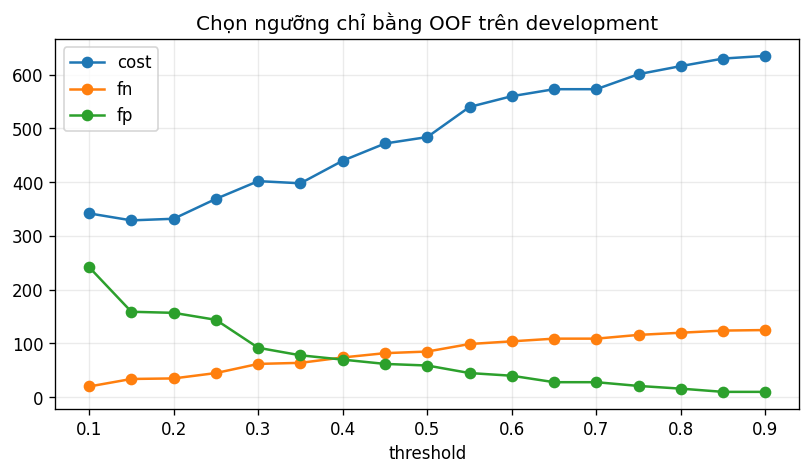

In [8]:
def decision_metrics(y_true,p,threshold,fn_cost=5,fp_cost=1):
    pred=(np.asarray(p)>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return dict(threshold=threshold,tn=tn,fp=fp,fn=fn,tp=tp,
                cost=fn_cost*fn+fp_cost*fp,
                recall=tp/(tp+fn) if tp+fn else 0,
                precision=tp/(tp+fp) if tp+fp else 0)

# Mô hình tham chiếu hoàn chỉnh để minh họa quy trình; NV2 có thể thay bằng cây đã chốt
reference_tree=DecisionTreeClassifier(max_depth=4,min_samples_leaf=10,random_state=SEED)
oof_prob=cross_val_predict(reference_tree,Xdev,ydev,cv=cv,method='predict_proba')[:,1]
thresholds=np.round(np.arange(.10,.91,.05),2)
threshold_table=pd.DataFrame([decision_metrics(ydev,oof_prob,t) for t in thresholds])
display(threshold_table)
ax=threshold_table.plot(x='threshold',y=['cost','fn','fp'],marker='o',figsize=(8,4))
ax.set_title('Chọn ngưỡng chỉ bằng OOF trên development'); ax.grid(alpha=.25); plt.show()
best_threshold=float(threshold_table.loc[threshold_table.cost.idxmin(),'threshold'])
print('Ngưỡng minh họa đã chốt:',best_threshold)
check('Mỗi mẫu có một OOF probability',len(oof_prob)==len(ydev))
check('Xác suất OOF hợp lệ',np.all((oof_prob>=0)&(oof_prob<=1)))
check('Ngưỡng nằm trong lưới',best_threshold in thresholds)

### Nhiệm vụ 4 - Phân tích chi phí và độ nhạy (1,5 điểm)

1. Viết lại `decision_metrics_student` không gọi hàm mẫu; kiểm thử ở ba trường hợp nhỏ.
2. Chọn ngưỡng bằng OOF cho mô hình đã chốt ở NV2 với FN:FP = 5:1.
3. Phân tích độ nhạy với FN cost = 2, 5, 10; giữ FP cost = 1. Lập bảng ngưỡng tối ưu, recall, precision, số cảnh báo và chi phí.
4. Viết 150-200 từ: trade-off, năng lực kiểm tra mỗi ngày, vì sao không được tối ưu trên test, và vì sao chi phí giả định phải được xác nhận ngoài thực địa.

In [9]:
def decision_metrics_student(y_true,p,threshold,fn_cost=5,fp_cost=1):
    # TODO: trả dictionary có tn,fp,fn,tp,cost,recall,precision,alerts
    raise NotImplementedError
RUN_NV4=False
if RUN_NV4:
    a=decision_metrics_student([0,0,1,1],[.1,.9,.2,.8],.5,5,1)
    assert (a['tn'],a['fp'],a['fn'],a['tp'])==(1,1,1,1) and a['cost']==6
    b=decision_metrics_student([0,1],[.4,.6],.5,5,1)
    assert b['cost']==0 and b['alerts']==1
    c=decision_metrics_student([0,1],[.6,.4],.5,10,2)
    assert c['cost']==12
    print('NV4: kiểm thử hàm đạt; tiếp tục bảng độ nhạy và phân tích.')
else: print('NV4 chưa hoàn thành.')

NV4 chưa hoàn thành.


## 5. Mở test một lần sau khi chốt mô hình và ngưỡng

Ô mẫu đánh giá `reference_tree` và `best_threshold` để minh họa. Khi nộp, sinh viên thay bằng **mô hình/ngưỡng đã chốt từ NV2-NV4**, chạy đúng một lần, không quay lại điều chỉnh. Báo cáo cả ngưỡng 0,5 và ngưỡng chi phí.

              precision    recall  f1-score   support

    no_alert       0.93      0.59      0.72        87
 early_check       0.45      0.88      0.59        33

    accuracy                           0.67       120
   macro avg       0.69      0.73      0.66       120
weighted avg       0.79      0.67      0.68       120

PASS: Đủ dự đoán test
PASS: Nhãn dự đoán hợp lệ


,rule,threshold,cost,recall_risk,precision_risk,FN,FP
0,default_0.50,0.50,105,0.484848,0.444444,17,20
1,cost_threshold,0.15,56,0.878788,0.446154,4,36


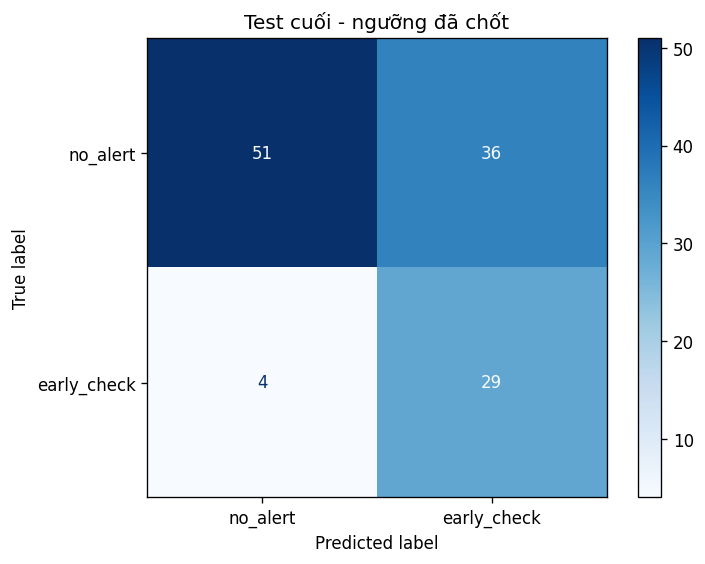

In [10]:
final_model=reference_tree.fit(Xdev,ydev)
test_prob=final_model.predict_proba(Xtest)[:,1]
test_rows=[]
for label,t in [('default_0.50',.5),('cost_threshold',best_threshold)]:
    m=decision_metrics(ytest,test_prob,t)
    test_rows.append([label,t,m['cost'],m['recall'],m['precision'],m['fn'],m['fp']])
test_table=pd.DataFrame(test_rows,columns=['rule','threshold','cost','recall_risk','precision_risk','FN','FP'])
display(test_table)
test_pred=(test_prob>=best_threshold).astype(int)
print(classification_report(ytest,test_pred,target_names=['no_alert','early_check'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(ytest,test_pred,display_labels=['no_alert','early_check'],cmap='Blues')
plt.title('Test cuối - ngưỡng đã chốt'); plt.tight_layout(); plt.show()
check('Đủ dự đoán test',len(test_pred)==len(ytest))
check('Nhãn dự đoán hợp lệ',set(test_pred)<={0,1})

## 6. Lập tuyến bằng A* trên bản đồ có trọng số

Bản đồ 12×12:

- `#`: ô cấm/không đi được;
- chi phí 1: đường thuận lợi;
- chi phí 2: lối đất;
- chi phí 4: vùng khó đi;
- kỹ thuật viên xuất phát tại `(11,0)`.

Chi phí tuyến là tổng chi phí **các ô được bước vào**, không tính ô xuất phát. Di chuyển 4 hướng. Heuristic Manhattan nhân với chi phí bước nhỏ nhất (=1) là admissible và consistent trong bản đồ này. A* phải cập nhật khi tìm được `g` tốt hơn; đánh dấu đóng khi lấy khỏi priority queue, không phải ngay khi sinh nút.

In [11]:
terrain=np.ones((12,12),dtype=int)
terrain[2:5,1:6]=2; terrain[7:10,5:11]=2
terrain[0:3,8:12]=4; terrain[5:8,0:4]=4
blocked={(1,6),(2,6),(3,6),(4,6),(5,6),(6,6),(8,3),(8,4),(9,4),(10,4),
         (4,9),(5,9),(6,9)}
start=(11,0)
plot_locations={'P01':(0,1),'P02':(1,10),'P03':(4,11),'P04':(6,2),'P05':(7,8),'P06':(10,10)}
def neighbors(pos):
    r,c=pos
    for dr,dc in [(-1,0),(1,0),(0,-1),(0,1)]:
        q=(r+dr,c+dc)
        if 0<=q[0]<12 and 0<=q[1]<12 and q not in blocked: yield q
def path_cost(path): return sum(terrain[p] for p in path[1:])

def astar_reference(start,goal):
    frontier=[(abs(start[0]-goal[0])+abs(start[1]-goal[1]),0,start)]
    came={start:None}; g={start:0}; closed=set(); expanded=0
    while frontier:
        f,current_g,current=heapq.heappop(frontier)
        if current in closed: continue
        closed.add(current); expanded+=1
        if current==goal:
            path=[]
            while current is not None: path.append(current); current=came[current]
            return path[::-1],g[goal],expanded
        for nxt in neighbors(current):
            ng=current_g+terrain[nxt]
            if ng<g.get(nxt,float('inf')):
                g[nxt]=ng; came[nxt]=current
                h=abs(nxt[0]-goal[0])+abs(nxt[1]-goal[1])
                heapq.heappush(frontier,(ng+h,ng,nxt))
    return None,float('inf'),expanded

sample_path,sample_cost,expanded=astar_reference(start,plot_locations['P01'])
print('Tuyến mẫu P01: bước=',len(sample_path)-1,'cost=',sample_cost,'expanded=',expanded)
check('Tuyến bắt đầu/kết thúc đúng',sample_path[0]==start and sample_path[-1]==plot_locations['P01'])
check('Các bước kề nhau',all(abs(a[0]-b[0])+abs(a[1]-b[1])==1 for a,b in zip(sample_path,sample_path[1:])))
check('Không đi qua ô cấm',not set(sample_path)&blocked)
check('Cost tính đúng',sample_cost==path_cost(sample_path))

Tuyến mẫu P01: bước= 12 cost= 21 expanded= 34
PASS: Tuyến bắt đầu/kết thúc đúng
PASS: Các bước kề nhau
PASS: Không đi qua ô cấm
PASS: Cost tính đúng


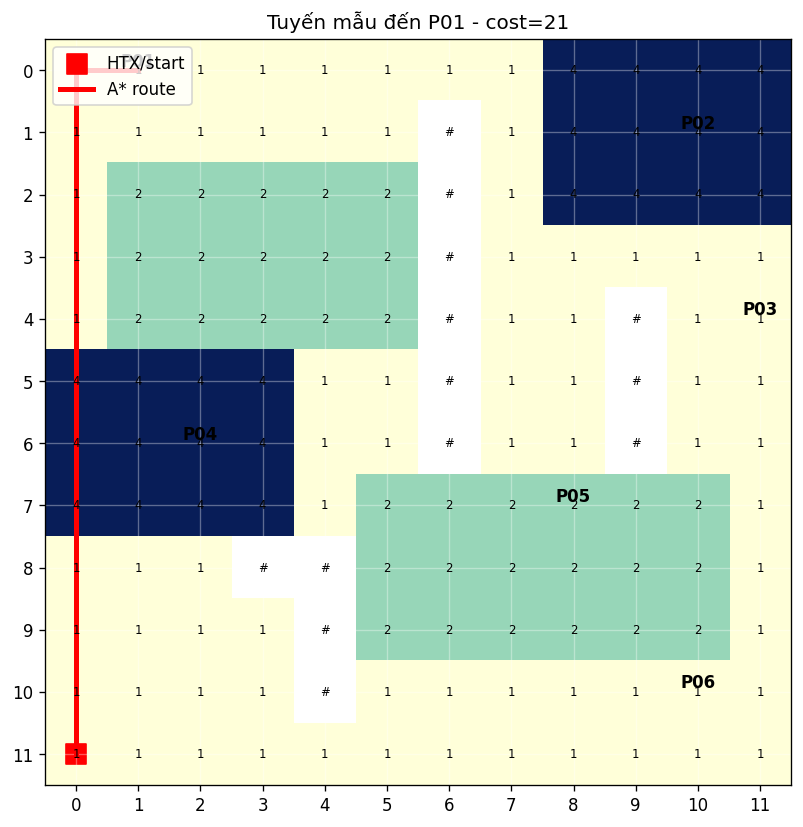

In [12]:
def draw_map(path=None,goals=None,title='Bản đồ điều phối'):
    arr=terrain.astype(float).copy()
    for p in blocked: arr[p]=np.nan
    fig,ax=plt.subplots(figsize=(7,7)); ax.imshow(arr,cmap='YlGnBu',vmin=1,vmax=4)
    for r in range(12):
        for c in range(12):
            ax.text(c,r,'#' if (r,c) in blocked else str(terrain[r,c]),ha='center',va='center',fontsize=7)
    ax.scatter(start[1],start[0],s=150,c='red',marker='s',label='HTX/start')
    for name,p in plot_locations.items(): ax.text(p[1],p[0],name,ha='center',va='bottom',weight='bold')
    if path:
        yy=[p[0] for p in path]; xx=[p[1] for p in path]; ax.plot(xx,yy,'r-',lw=3,label='A* route')
    ax.set_xticks(range(12));ax.set_yticks(range(12));ax.grid(color='white',alpha=.35)
    ax.set_title(title);ax.legend(loc='upper left');plt.tight_layout();plt.show()
draw_map(sample_path,title=f'Tuyến mẫu đến P01 - cost={sample_cost}')

### Nhiệm vụ 5 - Tự cài đặt A* và kiểm chứng tối ưu (2,0 điểm)

Hoàn thành `astar_student`. Không gọi `networkx` hoặc hàm mẫu. Hàm trả `(path, cost, expanded)`; nếu không tới được trả `(None, inf, expanded)`. Kiểm thử tất cả 6 lô bằng cách đối chiếu cost với Uniform Cost Search (A* với h=0) hoặc Dijkstra do sinh viên tự viết. Thêm một lô bị bao kín trong bản sao bản đồ để kiểm tra unreachable. Báo cáo số nút mở rộng A* và UCS; giải thích vì sao ít bước hơn chưa chắc ít chi phí hơn.

In [13]:
def astar_student(start,goal,terrain,blocked):
    # TODO: priority queue, g-score, came_from, Manhattan heuristic, reopen/update khi g tốt hơn
    raise NotImplementedError
RUN_NV5=False
if RUN_NV5:
    for name,goal in plot_locations.items():
        path,cost,expanded=astar_student(start,goal,terrain,blocked)
        ref_path,ref_cost,_=astar_reference(start,goal)
        assert path[0]==start and path[-1]==goal
        assert not set(path)&blocked
        assert cost==path_cost(path)==ref_cost
        print(name,'cost=',cost,'expanded=',expanded)
    print('NV5: 6 đích đạt; tiếp tục UCS, unreachable và phân tích.')
else: print('NV5 chưa hoàn thành.')

NV5 chưa hoàn thành.


## 7. Tích hợp dự báo và điều phối

Sáu lô đang chờ được kiểm tra có dữ liệu cảm biến mới. Hệ thống tính xác suất nguy cơ bằng mô hình đã chốt, áp dụng ngưỡng đã chốt, rồi bổ sung chi phí A*. Quy tắc minh họa:

1. ưu tiên các lô vượt ngưỡng cảnh báo;
2. trong nhóm cảnh báo, xếp xác suất giảm dần;
3. nếu xác suất bằng nhau, ưu tiên tuyến rẻ hơn;
4. bảng chỉ là **khuyến nghị**, kỹ thuật viên kiểm tra và ghi nhận kết quả thực tế.

Không dùng khoảng cách/tuyến đường để sửa xác suất bệnh. Đây là hai thành phần có vai trò khác nhau: mô hình ước lượng nguy cơ; A* tối ưu di chuyển đến mục tiêu được chọn.

PASS: Đủ 6 lô
PASS: Chi phí hữu hạn
PASS: Xác suất hợp lệ


,plot_id,risk_probability,alert,route_cost,steps,expanded
4,P05,0.538462,True,15,12,42
2,P03,0.538462,True,18,18,36
0,P01,0.538462,True,21,12,34
5,P06,0.096916,False,11,11,21
3,P04,0.096916,False,13,7,24
1,P02,0.096916,False,28,22,101


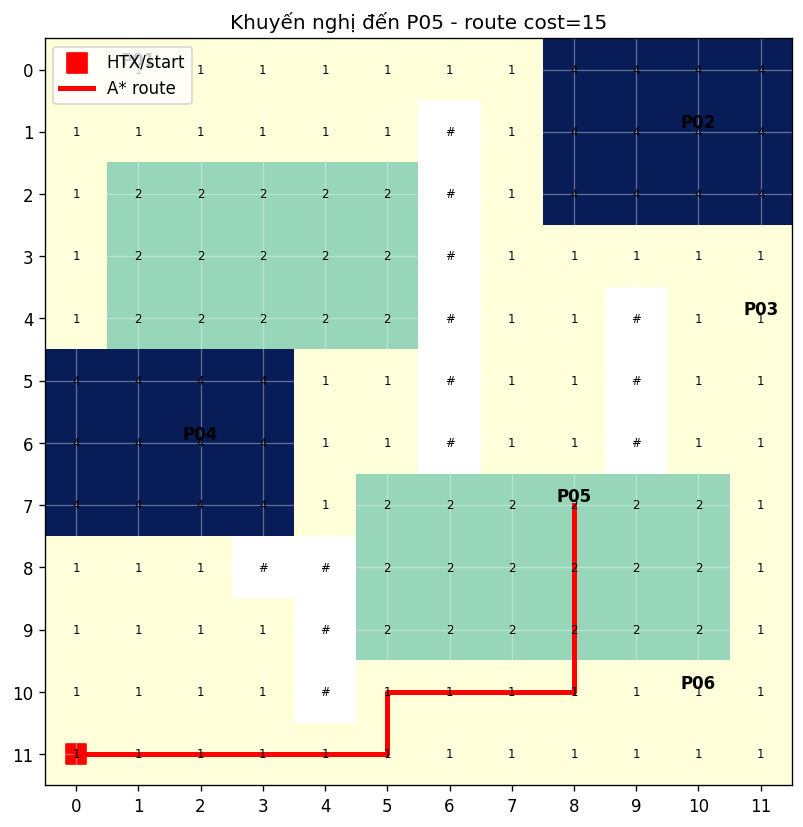

In [14]:
new_plots=pd.DataFrame([
['P01',19,35.8,86,.39,12,42],['P02',38,29.5,63,.74,3,4],
['P03',24,34.2,78,.51,10,18],['P04',44,31.0,70,.68,5,8],
['P05',16,37.1,84,.34,14,55],['P06',29,33.6,73,.57,8,12]],
columns=['plot_id',*features]).set_index('plot_id')
plot_prob=final_model.predict_proba(new_plots[features])[:,1]
recommend=[]
for pid,p in zip(new_plots.index,plot_prob):
    route,cost,exp=astar_reference(start,plot_locations[pid])
    recommend.append([pid,p,p>=best_threshold,cost,len(route)-1,exp])
recommend=pd.DataFrame(recommend,columns=['plot_id','risk_probability','alert','route_cost','steps','expanded'])
recommend=recommend.sort_values(['alert','risk_probability','route_cost'],ascending=[False,False,True])
display(recommend)
priority=next(iter(recommend.plot_id))
priority_path,priority_cost,_=astar_reference(start,plot_locations[priority])
draw_map(priority_path,title=f'Khuyến nghị đến {priority} - route cost={priority_cost}')
check('Đủ 6 lô',set(recommend.plot_id)==set(plot_locations))
check('Chi phí hữu hạn',np.isfinite(recommend.route_cost).all())
check('Xác suất hợp lệ',recommend.risk_probability.between(0,1).all())

### Nhiệm vụ 6 - Sản phẩm tích hợp và phản biện (1,5 điểm)

Thay `reference_tree` và `best_threshold` bằng kết quả NV2-NV4; dùng `astar_student` ở NV5. Tạo hàm `recommend_visit(model, threshold, plot_df, locations, start)` trả bảng có đủ: xác suất, cảnh báo, chi phí tuyến, số bước, thứ tự ưu tiên và lý do ngắn. Hàm phải:

- từ chối thiếu/sai tên cột hoặc vị trí không có trên bản đồ;
- không sửa DataFrame đầu vào;
- xử lý đích không tới được;
- xếp cảnh báo trước, rồi nguy cơ giảm dần, rồi chi phí tăng dần;
- sinh một câu khuyến nghị có điều kiện, không khẳng định chẩn đoán.

Viết 200-250 từ phản biện: dữ liệu mô phỏng, data drift, cảm biến lỗi, lệch chọn mẫu/nhãn, xác suất chưa hiệu chuẩn, chi phí giả định, giới hạn bản đồ tĩnh, an toàn và trách nhiệm con người. Đề xuất ít nhất ba KPI thí điểm thực địa và cơ chế phản hồi sau mỗi chuyến kiểm tra.

In [15]:
def recommend_visit(model,threshold,plot_df,locations,start):
    # TODO: validate -> predict -> A* -> rank -> reason; không sửa input
    raise NotImplementedError
RUN_NV6=False
if RUN_NV6:
    before=new_plots.copy(deep=True)
    table=recommend_visit(final_model,best_threshold,new_plots,plot_locations,start)
    pd.testing.assert_frame_equal(new_plots,before)
    assert set(['risk_probability','alert','route_cost','steps','priority','reason'])<=set(table.columns)
    assert table['priority'].tolist()==list(range(1,len(table)+1))
    assert table.risk_probability.between(0,1).all()
    print('NV6 đạt kiểm thử cấu trúc; tiếp tục trường hợp lỗi và phản biện.')
    display(table)
else: print('NV6 chưa hoàn thành.')

NV6 chưa hoàn thành.


## 8. Báo cáo, rubric và quy cách nộp

| Hạng mục | Điểm | Minh chứng tối thiểu |
|---|---:|---|
| NV1 - dữ liệu và T-E-P | 1,0 | Hàm audit, kiểm thử, nhận xét |
| NV2 - chọn Cây quyết định | 1,5 | GridSearchCV đúng, bảng, cây/luật, phân tích |
| NV3 - GaussianNB | 1,0 | Tính log-score, đối chiếu, đóng góp biến |
| NV4 - ngưỡng và chi phí | 1,5 | Hàm, OOF, độ nhạy chi phí, phân tích |
| NV5 - A* | 2,0 | Tự cài đặt, 6 đích, UCS, unreachable, giải thích |
| NV6 - tích hợp | 1,5 | Hàm khuyến nghị, kiểm tra lỗi, bảng điều phối, phản biện |
| Tái lập, báo cáo, vấn đáp | 1,5 | Run all 0,5; báo cáo 0,5; vấn đáp cá nhân 0,5 |
| **Tổng** | **10,0** | |

### Mẫu báo cáo điền trực tiếp

1. **Bài toán và T-E-P:** …
2. **Kiểm tra dữ liệu, rủi ro chất lượng dữ liệu:** …
3. **Bảng CV và lý do chọn mô hình:** …
4. **Giải thích một dự đoán Cây/Bayes:** …
5. **Ngưỡng, ma trận chi phí và độ nhạy:** …
6. **Kết quả test cuối và baseline:** …
7. **A*: heuristic, tính tối ưu, đối chiếu UCS:** …
8. **Bảng khuyến nghị tích hợp:** …
9. **Giới hạn, KPI thí điểm, trách nhiệm con người:** …
10. **Nguồn tham khảo, hỗ trợ AI và phân công nhóm:** …

### Câu hỏi vấn đáp

- Vì sao không được chọn mô hình hoặc ngưỡng trên test?
- Macro-F1 và recall lớp nguy cơ trả lời hai câu hỏi khác nhau thế nào?
- Vì sao Naive Bayes vẫn có thể tốt khi giả định độc lập không hoàn toàn đúng?
- Posterior cao có đồng nghĩa xác suất đã hiệu chuẩn không?
- Tại sao OOF probability phù hợp hơn train probability để chọn ngưỡng?
- Manhattan heuristic có còn admissible nếu cho phép đi chéo chi phí 1 không?
- A* khác Greedy Best-First ở đâu?
- Vì sao lô nguy cơ cao nhất chưa chắc là lô có tuyến rẻ nhất?
- Hệ thống nên làm gì khi cảm biến thiếu hoặc ngoài miền?
- Ai chịu trách nhiệm quyết định kiểm tra/xử lý ngoài thực địa?

### Quy cách nộp

Tên file: `MSSV_HoTen_BaiTongHop_AI_5Tiet.ipynb`. Trước khi nộp: Restart session → Run all; tất cả cờ NV1-NV6 phải `True`; giữ output; không đổi seed/chia dữ liệu nếu chưa được phép; không nộp ảnh thay notebook. Ghi rõ nguồn mã/tài liệu và mọi hỗ trợ AI. Điểm tự động không thay thế vấn đáp.

In [16]:
print(f'Đã đạt {len(CHECKS)} kiểm tra mã mẫu.')
print('Trạng thái:',dict(NV1=RUN_NV1,NV2=RUN_NV2,NV3=RUN_NV3,NV4=RUN_NV4,NV5=RUN_NV5,NV6=RUN_NV6))
print('Kiểm tra mã mẫu KHÔNG thay thế nhiệm vụ sinh viên, báo cáo và vấn đáp.')

Đã đạt 22 kiểm tra mã mẫu.
Trạng thái: {'NV1': False, 'NV2': False, 'NV3': False, 'NV4': False, 'NV5': False, 'NV6': False}
Kiểm tra mã mẫu KHÔNG thay thế nhiệm vụ sinh viên, báo cáo và vấn đáp.


## 9. Tài liệu tham khảo

**Tài liệu giảng viên cung cấp**

1. `COS521_Tri tue nhan tao.pdf`: CLO về tìm kiếm, A*, Cây quyết định, Bayes thơ ngây và phần thực hành.
2. `lecture9-Máy học.pdf`: quá trình học máy, Cây quyết định và Bayesian classification.
3. `Chuong 6-Cay quyet dinh.pdf`: ID3, entropy/information gain, quá khớp và tỉa cây.
4. `Chuong 3-Hoc dua tren xac suat.pdf`: MAP, Naive Bayes, làm trơn và log-score.

**Tài liệu kỹ thuật chính thức**

- [scikit-learn - Decision Trees](https://scikit-learn.org/stable/modules/tree.html)
- [scikit-learn - Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)
- [scikit-learn - Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn - Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [Python - heapq](https://docs.python.org/3/library/heapq.html)

Notebook phân biệt dữ liệu mô phỏng với bằng chứng thực địa. Mã mẫu ưu tiên khả năng kiểm tra và học tập, không phải hệ thống sản xuất.